# Predicción de la gravedad de siniestros viales en la Ciudad de Buenos Aires
## Notebook 2 — Modelo de clasificación: ¿el siniestro será leve, grave o mortal?

**3ª pre-entrega.** Modelo de clasificación de punta a punta: limpieza, análisis exploratorio orientado al objetivo, preparación de variables, ajuste de **Regresión Logística** y **Random Forest**, control del overfitting con optimización de hiperparámetros, evaluación y selección del modelo.

**Objetivo.** Dado un siniestro vial registrado en CABA, predecir su gravedad (`LEVE`, `GRAVE` o `MORTAL`) a partir de *cuándo* ocurrió, *dónde* y *quiénes* participaron. Un modelo así permite priorizar recursos (ambulancias, controles, obras) hacia los contextos con mayor probabilidad de víctimas graves o fatales.

| Parte | Qué se hace |
|---|---|
| 1 | Limpieza: se aplican las decisiones justificadas en el EDA (Notebook 1) |
| 2 | EDA orientado al modelo: ¿cómo se relaciona la gravedad con las demás variables? |
| 3 | Preparación: variables predictoras, fuga de información, codificación y división train/test |
| 4 | Modelos base y diagnóstico de overfitting |
| 5 | Optimización de hiperparámetros con validación cruzada |
| 6 | Evaluación final en test y selección del modelo |

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)
pd.set_option("display.max_columns", 60)

In [28]:
# En Colab hay que montar Drive; si no estamos en Colab, este paso se saltea.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    RUTA = "/content/drive/MyDrive/datos/"
except ImportError:
    RUTA = ""          # ejecución local: los CSV están en la misma carpeta del notebook

hechos_raw = pd.read_csv(RUTA + "siniestros_viales_hechos.csv",
                         sep=";", encoding="utf-8-sig", low_memory=False)
victimas_raw = pd.read_csv(RUTA + "siniestros_viales_victimas.csv",
                           sep=";", encoding="utf-8-sig", low_memory=False)

print("hechos  :", hechos_raw.shape)
print("victimas:", victimas_raw.shape)

hechos  : (65818, 21)
victimas: (75197, 9)


---
# Parte 1 — Limpieza de datos

Se aplican las decisiones que justificó el EDA del Notebook 1. Dos reglas:

1. **No se toca el crudo.** Todo se hace sobre una copia (`hechos`, `victimas`).
2. **Cada paso se mide.** Después de transformar se imprime cuántos valores cambiaron.

Orden: `copia → nombres → tipos → categorías → valores imposibles → faltantes → duplicados → coherencia → verificación → guardado`

## 1.1 Copia de trabajo y nombres de columnas

In [29]:
hechos = hechos_raw.copy()
victimas = victimas_raw.copy()

# Filas completamente vacías (las hay en victimas): no aportan nada
vacias = victimas.isna().all(axis=1).sum()
victimas = victimas.dropna(how="all")
print("filas completamente vacías eliminadas:", vacias)

# GRAVEdad_victima: un reemplazo automático del publicador rompió la caja del nombre
hechos.columns = hechos.columns.str.strip().str.lower()
victimas.columns = victimas.columns.str.strip().str.lower()

print(list(victimas.columns))

filas completamente vacías eliminadas: 4
['id_siniestro', 'fecha_siniestro', 'anio_siniestro', 'modo_desplazamiento_victima', 'sexo_victima', 'edad_victima', 'gravedad_victima', 'rol_victima', 'fecha_fallecimiento_victima']


## 1.2 Conversión de tipos

`errors="coerce"` convierte en faltante lo que no se puede interpretar (por ejemplo `"SD"`).

In [30]:
hechos["fecha_siniestro"] = pd.to_datetime(hechos["fecha_siniestro"], errors="coerce", format="mixed")
victimas["fecha_fallecimiento_victima"] = pd.to_datetime(victimas["fecha_fallecimiento_victima"],
                                                         errors="coerce", format="mixed")

# Hora (0-23), variables de calendario y comuna como número
hechos["hora"] = pd.to_datetime(hechos["hora_siniestro"], errors="coerce", format="mixed").dt.hour
hechos["dia_semana"] = hechos["fecha_siniestro"].dt.dayofweek
hechos["anio"] = hechos["fecha_siniestro"].dt.year
hechos["mes"] = hechos["fecha_siniestro"].dt.month
hechos["comuna"] = hechos["comuna_siniestro"].str.extract(r"(\d+)")[0].astype(float)

for columna in ["numero_total_de_victimas", "numero_victimas_leve_siniestro",
                "numero_victimas_grave_siniestro", "numero_victimas_mortal_siniestro",
                "latitud_siniestro", "longitud_siniestro"]:
    hechos[columna] = pd.to_numeric(hechos[columna], errors="coerce")

victimas["edad_victima"] = pd.to_numeric(victimas["edad_victima"], errors="coerce")

print("fechas de siniestro no interpretables:", hechos["fecha_siniestro"].isna().sum())

fechas de siniestro no interpretables: 0


## 1.3 Normalización de categorías

1. **Tipográfica**: quitar espacios → mayúsculas → sin acentos.
2. **Semántica**: diccionarios de equivalencias (`OMNIBUS` → `COLECTIVO`, `MOTOCICLETA` → `MOTO`).

`"SD"` y `"#¡REF!"` son faltantes disfrazados. Ojo: al quitar acentos, `"#¡REF!"` se convierte en `"#REF!"`, así que se reemplazan ambas formas.

In [31]:
categoricas_hechos = ["tipo_de_via_siniestro", "modo_desplazamiento_victima",
                      "contraparte_siniestro", "gravedad_siniestro"]
categoricas_victimas = ["sexo_victima", "gravedad_victima", "rol_victima",
                        "modo_desplazamiento_victima"]
faltantes_disfrazados = {"SD": "SIN DATOS", "#¡REF!": "SIN DATOS", "#REF!": "SIN DATOS"}

for columna in categoricas_hechos:
    hechos[columna] = (hechos[columna].str.strip().str.upper()
                       .str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii")
                       .replace(faltantes_disfrazados))

for columna in categoricas_victimas:
    victimas[columna] = (victimas[columna].str.strip().str.upper()
                         .str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii")
                         .replace(faltantes_disfrazados))

In [32]:
modo_equivalencias = {
    "AUTOMOVIL": "AUTO", "AUTO-UTILITARIO": "AUTO", "UTILITARIO": "AUTO",
    "CAMIONETA": "AUTO", "TAXI": "AUTO", "REMIS": "AUTO",
    "MOTOCICLETA": "MOTO", "CICLOMOTOR": "MOTO", "MOTOS": "MOTO",
    "BUS": "COLECTIVO", "OMNIBUS": "COLECTIVO", "MICRO": "COLECTIVO",
    "TRANSPORTE PUBLICO": "COLECTIVO",
    "BICI": "BICICLETA", "PEATONES": "PEATON", "CAMIONES": "CAMION",
}
gravedad_equivalencias = {"FATAL": "MORTAL", "FALLECIDO": "MORTAL",
                          "GRAVISIMO": "GRAVE", "LEVES": "LEVE"}
via_equivalencias = {"AV": "AVENIDA", "AVDA": "AVENIDA", "AV. GRAL. PAZ": "AUTOPISTA",
                     "AUTOPISTA URBANA": "AUTOPISTA", "CALLES": "CALLE"}
sexo_equivalencias = {"M": "MASCULINO", "F": "FEMENINO",
                      "VARON": "MASCULINO", "MUJER": "FEMENINO"}

hechos["modo_desplazamiento_victima"] = hechos["modo_desplazamiento_victima"].replace(modo_equivalencias)
hechos["contraparte_siniestro"] = hechos["contraparte_siniestro"].replace(modo_equivalencias)
hechos["tipo_de_via_siniestro"] = hechos["tipo_de_via_siniestro"].replace(via_equivalencias)
hechos["gravedad_siniestro"] = hechos["gravedad_siniestro"].replace(gravedad_equivalencias)

victimas["modo_desplazamiento_victima"] = victimas["modo_desplazamiento_victima"].replace(modo_equivalencias)
victimas["gravedad_victima"] = victimas["gravedad_victima"].replace(gravedad_equivalencias)
victimas["sexo_victima"] = victimas["sexo_victima"].replace(sexo_equivalencias)

hechos["modo_desplazamiento_victima"].value_counts(dropna=False)

modo_desplazamiento_victima
MOTO         24555
SIN DATOS    10929
PEATON        9415
AUTO          8580
BICICLETA     7091
COLECTIVO     3633
MOVIL          531
MIXTO          498
CAMION         250
MONOPATIN      207
OTRO           129
Name: count, dtype: int64

## 1.4 Valores imposibles → faltante

No se eliminan filas: el valor inválido pasa a faltante.

In [33]:
edad_invalida = ~victimas["edad_victima"].between(0, 110) & victimas["edad_victima"].notna()
victimas.loc[edad_invalida, "edad_victima"] = None

hora_invalida = ~hechos["hora"].between(0, 23) & hechos["hora"].notna()
hechos.loc[hora_invalida, "hora"] = None

comuna_invalida = ~hechos["comuna"].between(1, 15) & hechos["comuna"].notna()
hechos.loc[comuna_invalida, "comuna"] = None

coord_invalida = ((~hechos["latitud_siniestro"].between(-34.71, -34.52)
                   | ~hechos["longitud_siniestro"].between(-58.54, -58.33))
                  & hechos["latitud_siniestro"].notna())
hechos.loc[coord_invalida, ["latitud_siniestro", "longitud_siniestro"]] = None

print("edades inválidas     :", edad_invalida.sum())
print("horas inválidas      :", hora_invalida.sum())
print("comunas inválidas    :", comuna_invalida.sum())
print("coordenadas inválidas:", coord_invalida.sum())

edades inválidas     : 1
horas inválidas      : 0
comunas inválidas    : 0
coordenadas inválidas: 0


## 1.5 Valores faltantes

| Variable | Decisión | Por qué |
|---|---|---|
| Categóricas | nivel explícito `SIN DATOS` | imputar la moda inventa frecuencias |
| Conteos de víctimas | `0` | el vacío significa "ninguna víctima de esa gravedad" |
| `edad_victima` | se marca con `edad_imputada`; se imputa con la mediana | distribución asimétrica |
| `fecha_fallecimiento_victima`, coordenadas, `comuna` | **no se imputan** | vacío = no falleció / fallo de geocodificación |

In [34]:
conteos = ["numero_total_de_victimas", "numero_victimas_leve_siniestro",
           "numero_victimas_grave_siniestro", "numero_victimas_mortal_siniestro"]

hechos[conteos] = hechos[conteos].fillna(0)
hechos[categoricas_hechos] = hechos[categoricas_hechos].fillna("SIN DATOS")
victimas[categoricas_victimas] = victimas[categoricas_victimas].fillna("SIN DATOS")

victimas["edad_imputada"] = victimas["edad_victima"].isna()
victimas["edad_victima"] = victimas["edad_victima"].fillna(victimas["edad_victima"].median())

victimas["fallecio"] = victimas["fecha_fallecimiento_victima"].notna()

print("edades imputadas:", victimas["edad_imputada"].sum())
print("faltantes remanentes en hechos (%):")
print((hechos.isna().mean() * 100).round(2).sort_values(ascending=False).head(6))

edades imputadas: 23373
faltantes remanentes en hechos (%):
direccion_normalizada_siniestro    19.60
comuna                              5.40
longitud_siniestro                  4.61
latitud_siniestro                   4.61
comuna_siniestro                    4.58
geocodificacion_plana               3.60
dtype: float64


## 1.6 Duplicados y coherencia: la variable objetivo

- `hechos`: cualquier fila repetida sería un error de carga → se elimina.
- `victimas`: las filas idénticas son víctimas distintas (lo comprobó el EDA) → **no se eliminan**.
- **Variable objetivo (`gravedad`)**: se deriva de los conteos (MORTAL si hubo muertos, GRAVE si hubo graves, si no LEVE). Es verificable aritméticamente; la etiqueta de texto `gravedad_siniestro` se conserva sólo para auditar.

In [35]:
filas_antes = len(hechos)
hechos = hechos.drop_duplicates()
print("hechos:", filas_antes, "->", len(hechos))

hechos["gravedad"] = "LEVE"
hechos.loc[hechos["numero_victimas_grave_siniestro"] > 0, "gravedad"] = "GRAVE"
hechos.loc[hechos["numero_victimas_mortal_siniestro"] > 0, "gravedad"] = "MORTAL"

hechos["flag_gravedad_discrepante"] = ((hechos["gravedad_siniestro"] != "SIN DATOS") &
                                       (hechos["gravedad_siniestro"] != hechos["gravedad"]))
print("discrepancias declarada vs. derivada:", hechos["flag_gravedad_discrepante"].sum())

pd.crosstab(hechos["gravedad_siniestro"], hechos["gravedad"])

hechos: 65818 -> 65818
discrepancias declarada vs. derivada: 31


gravedad,GRAVE,LEVE,MORTAL
gravedad_siniestro,,,
GRAVE,2955,0,0
LEVE,31,62143,0
MORTAL,0,0,689


## 1.7 Verificación y guardado

In [36]:
print("Integridad referencial:")
print("  ids en victimas sin hecho    :", len(set(victimas["id_siniestro"]) - set(hechos["id_siniestro"])))
print("  hechos sin víctima registrada:", len(set(hechos["id_siniestro"]) - set(victimas["id_siniestro"])))

print("\nRangos después de la limpieza:")
print("  edad  :", victimas["edad_victima"].min(), "-", victimas["edad_victima"].max())
print("  hora  :", hechos["hora"].min(), "-", hechos["hora"].max())
print("  comuna:", hechos["comuna"].min(), "-", hechos["comuna"].max())

hechos.to_csv(RUTA + "hechos_limpio.csv", index=False, sep=";")
victimas.to_csv(RUTA + "victimas_limpio.csv", index=False, sep=";")
print("\nhechos_limpio  :", hechos.shape)
print("victimas_limpio:", victimas.shape)

Integridad referencial:
  ids en victimas sin hecho    : 0
  hechos sin víctima registrada: 0

Rangos después de la limpieza:
  edad  : 0.0 - 100.0
  hora  : 0.0 - 23.0
  comuna: 1.0 - 15.0

hechos_limpio  : (65818, 28)
victimas_limpio: (75193, 11)


---
# Parte 2 — EDA orientado al modelo

El Notebook 1 diagnosticó la calidad de los datos. Acá la pregunta es otra: **¿qué variables se asocian con la gravedad?** Eso orienta la selección de predictoras.

## 2.1 Distribución de la variable objetivo

gravedad
LEVE      62143
GRAVE      2986
MORTAL      689
Name: count, dtype: int64
gravedad
LEVE      94.42
GRAVE      4.54
MORTAL     1.05
Name: proportion, dtype: float64


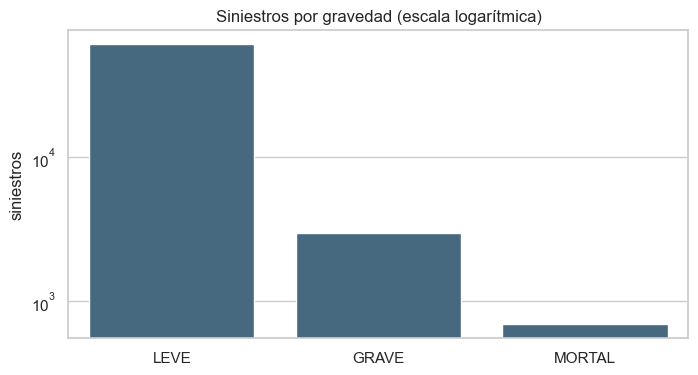

In [37]:
orden_gravedad = ["LEVE", "GRAVE", "MORTAL"]

print(hechos["gravedad"].value_counts())
print((hechos["gravedad"].value_counts(normalize=True) * 100).round(2))

sns.countplot(x=hechos["gravedad"], order=orden_gravedad, color="#3E6B89")
plt.yscale("log")
plt.title("Siniestros por gravedad (escala logarítmica)")
plt.xlabel("")
plt.ylabel("siniestros")
plt.show()

**Lectura.** La clase está **fuertemente desbalanceada**: alrededor del 94 % de los siniestros son leves, 4,5 % graves y 1 % mortales. Tres consecuencias para el modelado:

1. Un modelo que prediga siempre `LEVE` tendría ~94 % de *accuracy* sin servir para nada: el accuracy **no** sirve como métrica principal.
2. La división train/test tiene que ser **estratificada** para que las clases raras estén en ambos conjuntos.
3. Los modelos necesitan **ponderar las clases** (`class_weight`), si no aprenden a ignorar las graves y mortales.

## 2.2 Gravedad según quién es la víctima y contra qué choca

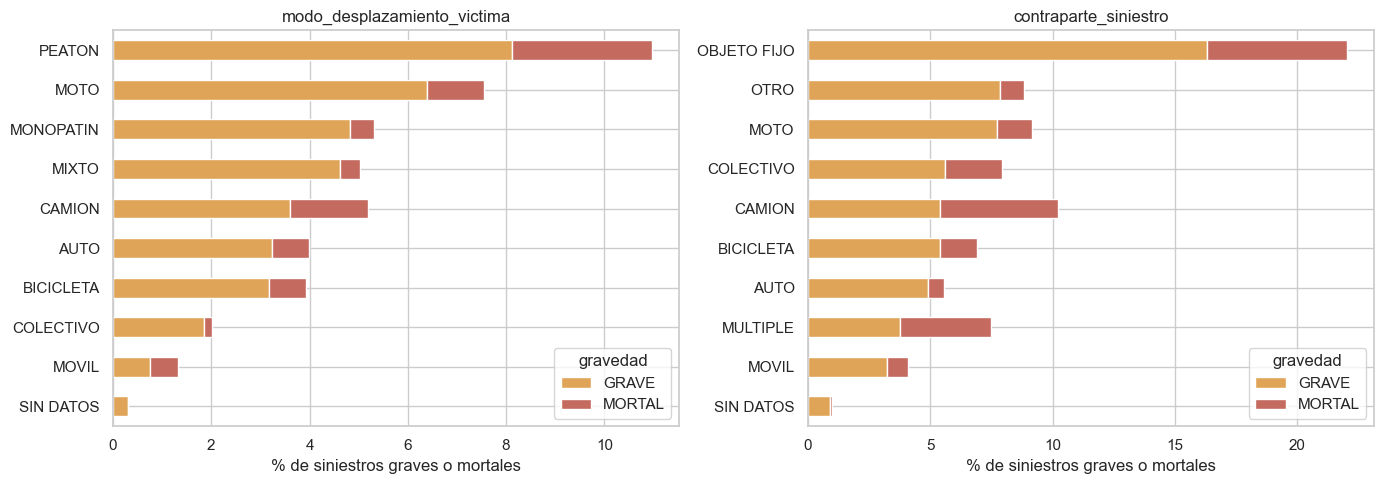

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, columna in zip(axes, ["modo_desplazamiento_victima", "contraparte_siniestro"]):
    tabla = pd.crosstab(hechos[columna], hechos["gravedad"], normalize="index")[["GRAVE", "MORTAL"]] * 100
    tabla = tabla.loc[hechos[columna].value_counts().index[:10]]     # las 10 categorías más frecuentes
    tabla.sort_values("GRAVE").plot(kind="barh", stacked=True, ax=ax, color=["#E0A458", "#C46A5E"])
    ax.set_title(columna)
    ax.set_xlabel("% de siniestros graves o mortales")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

**Lectura.** El **peatón** es la víctima con mayor proporción de siniestros graves y mortales (~11 %), seguido por la **moto** y el **monopatín**; quienes viajan en colectivo casi nunca sufren lesiones graves. Del lado de la contraparte, chocar contra un **objeto fijo** es lo más grave (más del 20 %) y el **camión** concentra la mayor proporción de siniestros mortales. La categoría `SIN DATOS` es casi siempre leve: refleja que los siniestros leves se registran con menos detalle (un sesgo de la fuente que el modelo va a aprender).

## 2.3 Gravedad según el momento y el lugar

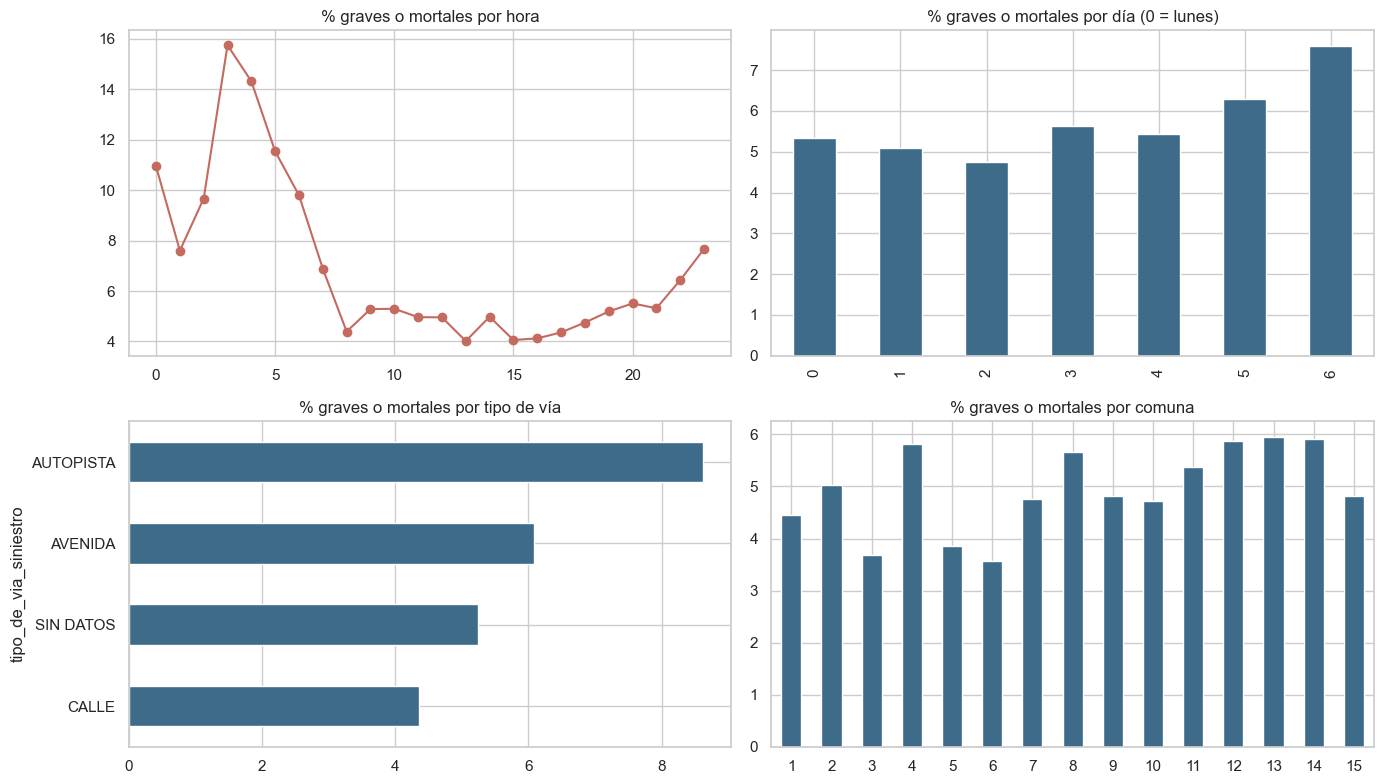

In [39]:
grave_o_mortal = hechos["gravedad"].isin(["GRAVE", "MORTAL"])

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

(grave_o_mortal.groupby(hechos["hora"]).mean() * 100).plot(ax=axes[0, 0], marker="o", color="#C46A5E")
axes[0, 0].set_title("% graves o mortales por hora")

(grave_o_mortal.groupby(hechos["dia_semana"]).mean() * 100).plot(kind="bar", ax=axes[0, 1], color="#3E6B89")
axes[0, 1].set_title("% graves o mortales por día (0 = lunes)")

(grave_o_mortal.groupby(hechos["tipo_de_via_siniestro"]).mean() * 100).sort_values().plot(
    kind="barh", ax=axes[1, 0], color="#3E6B89")
axes[1, 0].set_title("% graves o mortales por tipo de vía")

(grave_o_mortal.groupby(hechos["comuna"]).mean() * 100).plot(kind="bar", ax=axes[1, 1], color="#3E6B89")
axes[1, 1].set_title("% graves o mortales por comuna")
axes[1, 1].set_xticklabels(range(1, 16), rotation=0)

for ax in axes.ravel():
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Lectura.** La proporción de siniestros graves o mortales **se triplica de madrugada** (pico de ~16 % a las 3 h, contra ~4 % a la tarde: menos tránsito, más velocidad) y es más alta los **fines de semana**, sobre todo el domingo; es mayor en **autopistas** que en calles. Entre comunas hay diferencias moderadas. Todas estas variables entran como predictoras.

---
# Parte 3 — Preparación de los datos para el modelo

## 3.1 Unidad de análisis y fuga de información

La unidad es el **siniestro** (una fila de `hechos`). Hay que excluir toda variable que **contenga la respuesta** o que sólo se conozca después de saber la gravedad (*data leakage*):

| Variable excluida | Motivo |
|---|---|
| `numero_victimas_{leve,grave,mortal}_siniestro` | con ellas se construye la variable objetivo |
| `gravedad_siniestro`, flags de gravedad | son la variable objetivo con otra etiqueta |
| `gravedad_victima`, `fecha_fallecimiento_victima`, `fallecio` (tabla `victimas`) | describen el resultado del siniestro |
| `numero_total_de_victimas` | tiene ~5 % de valores `SD` e incoherencias; se reemplaza por la cantidad de filas en `victimas` |
| dirección, coordenadas, `id_siniestro` | identificadores o texto libre; la ubicación entra a través de `comuna` |

## 3.2 Variables que se agregan desde la tabla `victimas`

De `victimas` (una fila por persona) se resumen dos variables a nivel siniestro: cuántas víctimas hubo y su edad promedio. Para la edad se usan sólo las edades **observadas** (no las imputadas con la mediana en la limpieza), así la imputación no aplana la variable.

In [40]:
edad_observada = victimas["edad_victima"].where(~victimas["edad_imputada"])

resumen_victimas = (victimas.assign(edad_observada=edad_observada)
                    .groupby("id_siniestro")
                    .agg(cantidad_victimas=("id_siniestro", "size"),
                         edad_media_victimas=("edad_observada", "mean")))

datos = hechos.merge(resumen_victimas, on="id_siniestro", how="left")
datos[["cantidad_victimas", "edad_media_victimas"]].describe().round(2)

,cantidad_victimas,edad_media_victimas
count,65818.00,45258.00
mean,1.14,38.14
std,0.54,15.44
min,1.00,0.00
25%,1.00,27.00
50%,1.00,35.00
75%,1.00,47.00
max,26.00,100.00


## 3.3 Selección de variables y tratamiento de faltantes

- **Numéricas:** `hora`, `dia_semana`, `mes`, `anio`, `cantidad_victimas`, `edad_media_victimas`.
- **Categóricas:** `tipo_de_via_siniestro`, `modo_desplazamiento_victima`, `contraparte_siniestro`, `comuna`.

`comuna` es un código de zona, no una cantidad: va como categórica, y sus faltantes forman el nivel `SIN DATOS`. Los pocos faltantes de `hora` y de `edad_media_victimas` se completan con la mediana.

In [41]:
numericas = ["hora", "dia_semana", "mes", "anio", "cantidad_victimas", "edad_media_victimas"]
categoricas = ["tipo_de_via_siniestro", "modo_desplazamiento_victima", "contraparte_siniestro", "comuna"]

datos_modelo = datos[numericas + categoricas + ["gravedad"]].copy()

# comuna faltante -> 0 -> "SIN DATOS"; el resto pasa a texto ("1" a "15")
datos_modelo["comuna"] = datos_modelo["comuna"].fillna(0).astype(int).astype(str).replace("0", "SIN DATOS")
datos_modelo["hora"] = datos_modelo["hora"].fillna(datos_modelo["hora"].median())
datos_modelo["edad_media_victimas"] = datos_modelo["edad_media_victimas"].fillna(
    datos_modelo["edad_media_victimas"].median())

print("faltantes:", datos_modelo.isna().sum().sum())
datos_modelo.head()

faltantes: 0


,hora,dia_semana,mes,anio,cantidad_victimas,edad_media_victimas,tipo_de_via_siniestro,modo_desplazamiento_victima,contraparte_siniestro,comuna,gravedad
0,1.0,1,1,2019,1,57.000000,AUTOPISTA,AUTO,AUTO,8,LEVE
1,18.0,1,1,2019,1,54.000000,AVENIDA,MOTO,AUTO,12,GRAVE
2,13.0,1,1,2019,3,40.333333,SIN DATOS,AUTO,AUTO,11,LEVE
3,7.0,1,1,2019,1,33.000000,SIN DATOS,AUTO,CAMION,9,LEVE
4,12.0,1,1,2019,1,23.000000,SIN DATOS,AUTO,MOVIL,4,LEVE


## 3.4 Codificación y división en train y test

Las categóricas se transforman con *one-hot encoding* (`pd.get_dummies`). Se separa un 20 % para test con `stratify=y`, para que las proporciones de `GRAVE` y `MORTAL` sean las mismas en ambos conjuntos.

In [42]:
X = pd.get_dummies(datos_modelo.drop(columns=["gravedad"]), columns=categoricas, drop_first=True)
y = datos_modelo["gravedad"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Variables predictoras:", X.shape[1])
print("Train:", X_train.shape, " Test:", X_test.shape)

pd.DataFrame({"train": y_train.value_counts(normalize=True),
              "test": y_test.value_counts(normalize=True)}).round(4)

Variables predictoras: 46
Train: (52654, 46)  Test: (13164, 46)


,train,test
gravedad,,
LEVE,0.9442,0.9442
GRAVE,0.0454,0.0454
MORTAL,0.0105,0.0105


---
# Parte 4 — Modelos base

## 4.1 Métricas

Con clases desbalanceadas se usan métricas **macro**: se calculan para cada clase y se promedian dando **el mismo peso** a `LEVE`, `GRAVE` y `MORTAL`.

- **Precision macro**: de los siniestros que el modelo predice de cada clase, cuántos lo son.
- **Recall macro**: de los siniestros de cada clase, cuántos detecta.
- **F1 macro** (métrica principal): equilibrio entre precision y recall. Un modelo que ignore las clases raras obtiene F1 macro bajo aunque su accuracy sea alto.

## 4.2 Línea de base, Regresión Logística y Random Forest

- **Línea de base** (`DummyClassifier`): predice siempre la clase más frecuente. Cualquier modelo útil tiene que superarla.
- **Regresión Logística**: sensible a la escala de las variables, así que se estandariza dentro de un `Pipeline` (el escalador se ajusta sólo con los datos de entrenamiento). `class_weight="balanced"` pondera cada clase de forma inversa a su frecuencia.
- **Random Forest**: no necesita escalado. Se entrena primero **sin restringir** la profundidad de los árboles, para ver qué pasa.

In [43]:
modelo_base = DummyClassifier(strategy="most_frequent")
modelo_base.fit(X_train, y_train)

modelo_logistica = make_pipeline(StandardScaler(),
                                 LogisticRegression(class_weight="balanced", max_iter=2000))
modelo_logistica.fit(X_train, y_train)

modelo_rf = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                                   random_state=42, n_jobs=-1)
modelo_rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

## 4.3 Diagnóstico de overfitting: train vs. test

Si un modelo tiene métricas mucho mejores en train que en test, **memorizó** los datos de entrenamiento en lugar de aprender patrones generalizables.

In [44]:
modelos_base = {"Línea de base": modelo_base,
                "Regresión Logística": modelo_logistica,
                "Random Forest (sin restricciones)": modelo_rf}

resultados_base = []
for nombre, modelo in modelos_base.items():
    resultados_base.append({
        "Modelo": nombre,
        "Accuracy test": accuracy_score(y_test, modelo.predict(X_test)),
        "F1 macro train": f1_score(y_train, modelo.predict(X_train), average="macro"),
        "F1 macro test": f1_score(y_test, modelo.predict(X_test), average="macro"),
    })

pd.DataFrame(resultados_base).round(3)

,Modelo,Accuracy test,F1 macro train,F1 macro test
0,Línea de base,0.944,0.324,0.324
1,Regresión Logística,0.613,0.337,0.335
2,Random Forest (sin restricciones),0.944,1.000,0.349


**Lectura.**

- La **línea de base** confirma la trampa del accuracy: ~94 % sin detectar un solo siniestro grave o mortal (F1 macro ≈ 0,32).
- La **Regresión Logística** rinde igual en train y en test: no sobreajusta, pero su F1 macro apenas supera a la línea de base. A diferencia de ella sí detecta siniestros graves y mortales, pero a costa de muchas falsas alarmas: es un modelo lineal y no capta interacciones (por ejemplo, *peatón × madrugada × autopista*).
- El **Random Forest sin restricciones** tiene un F1 casi perfecto en train y mucho más bajo en test: **overfitting** claro. Sus árboles crecen hasta aislar cada siniestro del entrenamiento.

La forma de corregirlo es limitar la complejidad del modelo (profundidad de los árboles, mínimo de observaciones por hoja) y elegir esos hiperparámetros con **validación cruzada**, sin usar el test.

---
# Parte 5 — Optimización de hiperparámetros

`GridSearchCV` prueba todas las combinaciones de una grilla de hiperparámetros con **validación cruzada estratificada de 3 pliegues** sobre el conjunto de entrenamiento, y elige la de mayor **F1 macro promedio en validación**.

## 5.1 Regresión Logística

El hiperparámetro principal es `C`, la inversa de la regularización: un `C` chico penaliza coeficientes grandes (modelo más simple); un `C` grande deja al modelo ajustarse más a los datos.

In [45]:
validacion = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grilla_logistica = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)),
    param_grid={"logisticregression__C": [0.0001, 0.001, 0.01, 0.1, 1]},
    scoring="f1_macro", cv=validacion, return_train_score=True, n_jobs=-1)

grilla_logistica.fit(X_train, y_train)

print("Mejor C:", grilla_logistica.best_params_)
print("F1 macro en validación:", round(grilla_logistica.best_score_, 3))

pd.DataFrame(grilla_logistica.cv_results_)[
    ["param_logisticregression__C", "mean_train_score", "mean_test_score"]].round({"mean_train_score": 3,
                                                                                  "mean_test_score": 3})

Mejor C: {'logisticregression__C': 0.0001}
F1 macro en validación: 0.345


,param_logisticregression__C,mean_train_score,mean_test_score
0,0.0001,0.348,0.345
1,0.0010,0.340,0.339
2,0.0100,0.338,0.336
3,0.1000,0.337,0.335
4,1.0000,0.337,0.334


**Lectura.** Train y validación casi coinciden para todo `C` (no hay overfitting) y las diferencias entre valores son menores a 0,01: la regularización casi no cambia el resultado. El límite de la Regresión Logística no está en sus hiperparámetros sino en su forma lineal.

## 5.2 Random Forest

- `max_depth`: profundidad máxima de cada árbol.
- `min_samples_leaf`: mínimo de siniestros en cada hoja; valores altos impiden que el árbol aísle casos individuales.

Ambos controlan la complejidad del modelo y, por lo tanto, el overfitting. *(Esta celda tarda unos minutos.)*

In [46]:
grilla_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                           random_state=42, n_jobs=-1),
    param_grid={"max_depth": [10, 20, 30, None],
                "min_samples_leaf": [1, 5, 10]},
    scoring="f1_macro", cv=validacion, return_train_score=True, n_jobs=-1)

grilla_rf.fit(X_train, y_train)

print("Mejores hiperparámetros:", grilla_rf.best_params_)
print("F1 macro en validación:", round(grilla_rf.best_score_, 3))

Mejores hiperparámetros: {'max_depth': None, 'min_samples_leaf': 5}
F1 macro en validación: 0.484


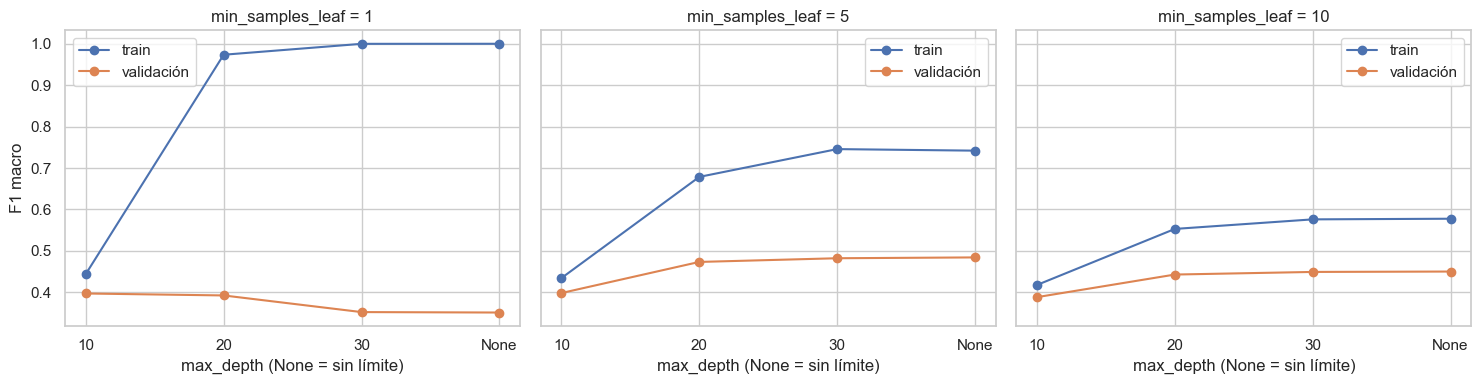

In [47]:
# Curva de complejidad: F1 macro en train y en validación según la profundidad
resultados_rf = pd.DataFrame(grilla_rf.cv_results_)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, hoja in zip(axes, [1, 5, 10]):
    curva = resultados_rf[resultados_rf["param_min_samples_leaf"] == hoja]
    profundidad = [str(p["max_depth"]) for p in curva["params"]]
    ax.plot(profundidad, curva["mean_train_score"], marker="o", label="train")
    ax.plot(profundidad, curva["mean_test_score"], marker="o", label="validación")
    ax.set_title(f"min_samples_leaf = {hoja}")
    ax.set_xlabel("max_depth (None = sin límite)")
    ax.legend()

axes[0].set_ylabel("F1 macro")
plt.tight_layout()
plt.show()

**Lectura.** A medida que crece la profundidad, el F1 en **train** sube sin freno, pero el F1 en **validación** mejora cada vez menos: la brecha entre ambas curvas es el overfitting. Subir `min_samples_leaf` achica esa brecha a costa de algo de rendimiento. `GridSearchCV` elige la combinación con mejor F1 en validación, que es el criterio que importa para datos nuevos.

---
# Parte 6 — Evaluación final y selección del modelo

Recién ahora se usa el conjunto de **test**, una sola vez, con los modelos optimizados.

## 6.1 Comparación de métricas

In [48]:
modelo_logistica_opt = grilla_logistica.best_estimator_
modelo_rf_opt = grilla_rf.best_estimator_

modelos_finales = {"Línea de base": modelo_base,
                   "Regresión Logística (optimizada)": modelo_logistica_opt,
                   "Random Forest (sin restricciones)": modelo_rf,
                   "Random Forest (optimizado)": modelo_rf_opt}

resultados = []
for nombre, modelo in modelos_finales.items():
    predicciones = modelo.predict(X_test)
    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, predicciones),
        "Precision macro": precision_score(y_test, predicciones, average="macro", zero_division=0),
        "Recall macro": recall_score(y_test, predicciones, average="macro"),
        "F1 macro": f1_score(y_test, predicciones, average="macro"),
        "F1 macro train": f1_score(y_train, modelo.predict(X_train), average="macro"),
    })

df_resultados = pd.DataFrame(resultados).set_index("Modelo").round(3)
df_resultados

,Accuracy,Precision macro,Recall macro,F1 macro,F1 macro train
Modelo,,,,,
Línea de base,0.944,0.315,0.333,0.324,0.324
Regresión Logística (optimizada),0.641,0.374,0.606,0.343,0.346
Random Forest (sin restricciones),0.944,0.497,0.346,0.349,1.000
Random Forest (optimizado),0.899,0.457,0.542,0.486,0.726


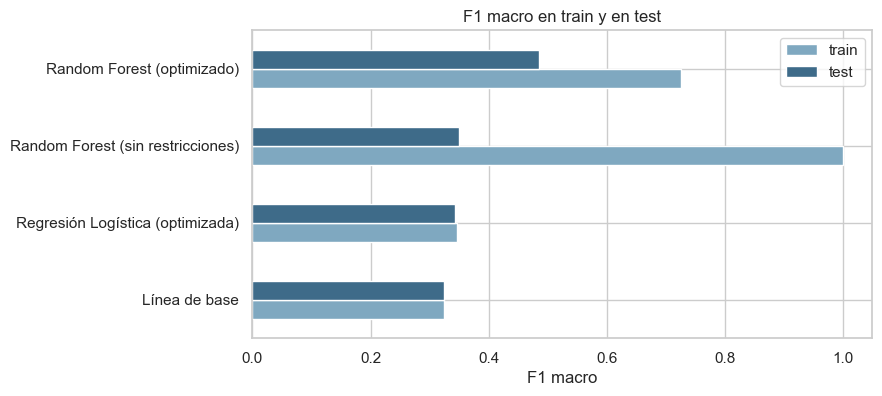

In [49]:
df_resultados[["F1 macro train", "F1 macro"]].plot(kind="barh", color=["#7FA8C0", "#3E6B89"])
plt.title("F1 macro en train y en test")
plt.xlabel("F1 macro")
plt.ylabel("")
plt.legend(["train", "test"])
plt.show()

## 6.2 Rendimiento por clase

El promedio macro esconde lo más importante: **¿cuántos siniestros graves y mortales detecta cada modelo?**

In [50]:
print("REGRESIÓN LOGÍSTICA (optimizada)")
print(classification_report(y_test, modelo_logistica_opt.predict(X_test), digits=3))

print("RANDOM FOREST (optimizado)")
print(classification_report(y_test, modelo_rf_opt.predict(X_test), digits=3))

REGRESIÓN LOGÍSTICA (optimizada)
              precision    recall  f1-score   support

       GRAVE      0.096     0.461     0.159       597
        LEVE      0.979     0.649     0.780     12429
      MORTAL      0.048     0.710     0.089       138

    accuracy                          0.641     13164
   macro avg      0.374     0.606     0.343     13164
weighted avg      0.929     0.641     0.745     13164

RANDOM FOREST (optimizado)
              precision    recall  f1-score   support

       GRAVE      0.229     0.338     0.273       597
        LEVE      0.965     0.932     0.948     12429
      MORTAL      0.178     0.355     0.237       138

    accuracy                          0.899     13164
   macro avg      0.457     0.542     0.486     13164
weighted avg      0.923     0.899     0.910     13164



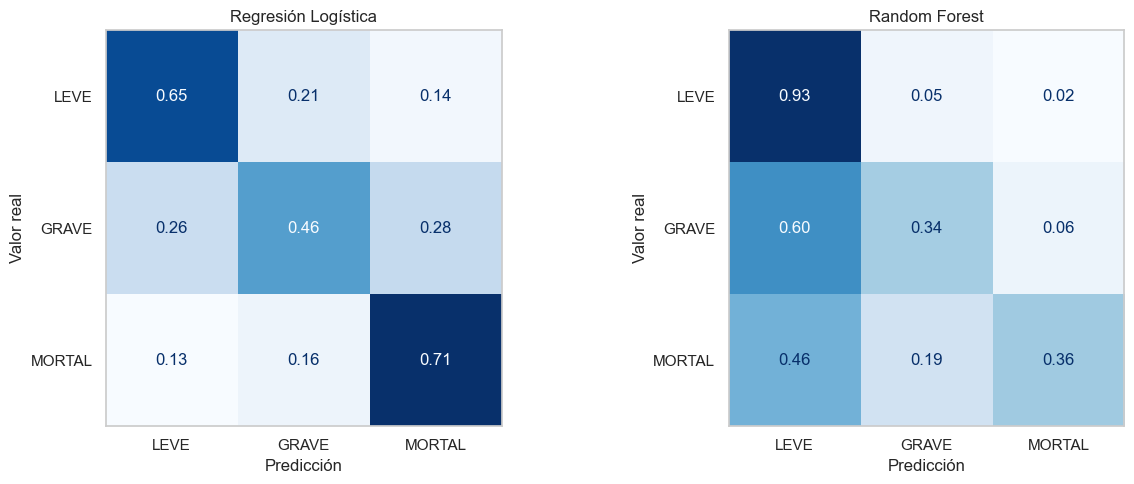

In [51]:
# Matrices de confusión normalizadas por fila: cada fila muestra cómo se clasificaron
# los siniestros de esa clase real (la diagonal es el recall de cada clase)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (nombre, modelo) in zip(axes, [("Regresión Logística", modelo_logistica_opt),
                                       ("Random Forest", modelo_rf_opt)]):
    ConfusionMatrixDisplay.from_estimator(modelo, X_test, y_test, labels=orden_gravedad,
                                          normalize="true", values_format=".2f",
                                          cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(nombre)
    ax.grid(False)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")

plt.tight_layout()
plt.show()

## 6.3 ¿Qué variables usa el Random Forest?

La importancia de cada variable mide cuánto reduce, en promedio, la impureza de los árboles al usarla para dividir.

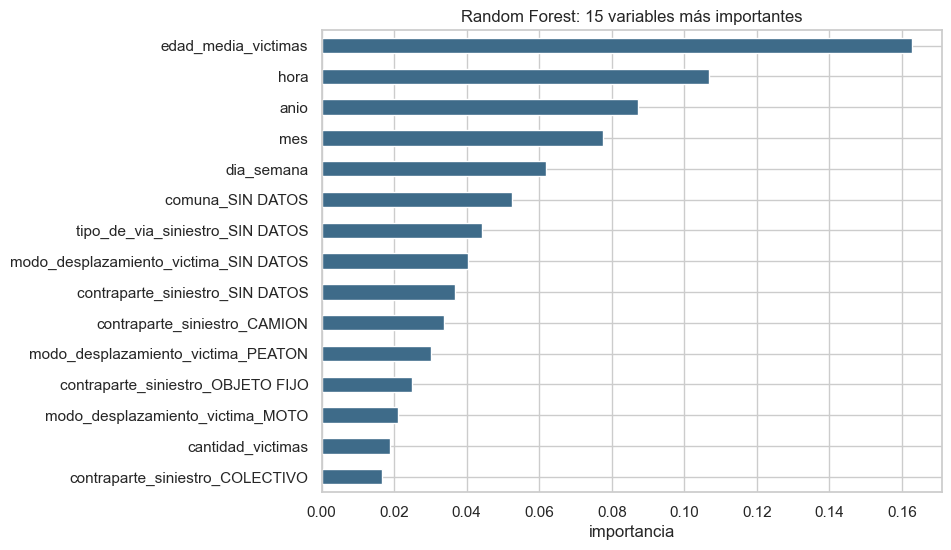

In [52]:
importancias = pd.Series(modelo_rf_opt.feature_importances_, index=X.columns).sort_values()

importancias.tail(15).plot(kind="barh", color="#3E6B89", figsize=(8, 6))
plt.title("Random Forest: 15 variables más importantes")
plt.xlabel("importancia")
plt.show()

## 6.4 Selección del modelo y conclusiones

**Comparación de los dos modelos optimizados (test):**

| | Regresión Logística | Random Forest |
|---|---|---|
| F1 macro | ≈ 0,34 | **≈ 0,48** |
| Recall GRAVE / MORTAL | **≈ 0,46 / 0,71** | ≈ 0,33 / 0,36 |
| Precision GRAVE / MORTAL | ≈ 0,10 / 0,05 | **≈ 0,22 / 0,17** |
| Accuracy | ≈ 0,64 | ≈ 0,90 |

**Modelo seleccionado: Random Forest optimizado** (`max_depth=30`, `min_samples_leaf=5`, `class_weight="balanced_subsample"`). Criterio: mayor **F1 macro en validación cruzada**, la métrica definida antes de mirar el test, que equilibra detectar los siniestros graves y mortales con no llenar de falsas alarmas. El resultado en test lo confirma.

**Por qué no la Regresión Logística.** Detecta más graves y mortales (mayor recall), pero de cada 100 siniestros que marca como mortales sólo ~5 lo son, y clasifica mal a más de un tercio de los leves. Como herramienta para priorizar recursos generaría demasiadas alarmas. Podría preferirse sólo si el costo de no detectar un siniestro mortal fuera muchísimo mayor que el de una falsa alarma.

**Overfitting.** Pasar del Random Forest sin restricciones al optimizado bajó el F1 macro en train de 1,00 a ≈ 0,72 y lo **subió** en test de ≈ 0,35 a ≈ 0,48: limitar la complejidad mejoró la generalización. Todavía queda una brecha train–test, propia de un problema con clases tan raras, pero es la combinación que mejor rinde en validación.

**Variables más relevantes.** Edad de las víctimas, hora, año, mes y día de la semana, seguidas del tipo de víctima (peatón, moto) y de la contraparte (camión, objeto fijo), en línea con el EDA de la Parte 2. Dos advertencias: la importancia por impureza favorece a las variables numéricas con muchos valores distintos, y las categorías `SIN DATOS` son importantes porque los siniestros leves se registran con menos detalle: el modelo aprende en parte **cómo se carga el dato**, no sólo cómo ocurre el siniestro.

**Limitaciones y próximos pasos.**

- La tarea es difícil: con la información disponible al momento del hecho, incluso el mejor modelo detecta sólo un tercio de los siniestros graves y mortales.
- Sumar variables de contexto (velocidad máxima de la vía, iluminación, clima, intersección vs. tramo) probablemente mejoraría la detección.
- Ajustar el **umbral de decisión** con `predict_proba` permitiría mover el equilibrio entre recall y precision según el uso (por ejemplo, priorizar recall para despacho de emergencias).
- Validar con una división **temporal** (entrenar con 2019–2023 y evaluar en 2024–2025) mediría mejor el rendimiento sobre siniestros futuros.